# **Business Case: Scaler - Clustering**

**1. Problem Statement & Exploratory Data Analysis**

Scaler wants to profile and cluster learners based on their job profiles, current companies, years of experience, and CTC (compensation). By clustering learners effectively, Scaler can identify top-tier employers, key job roles, high-performing learner segments, and compensation benchmarks to better assist with career transitions and targeted mentoring.

---



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import datetime

# Machine Learning & Stats
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import pdist, squareform

# Set Style for visualizations
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('viridis')
pd.set_option('display.max_columns', None)

print("Environment setup complete!")

Environment setup complete!


In [7]:
# The unique ID from your Google Drive link
file_id = '1KfJBgMjr-1eZvM0jinGIA9BXr8WLn1kF'

# Construct the direct download URL
csv_url = f'https://drive.google.com/uc?export=download&id={file_id}'


In [8]:
try:
    df = pd.read_csv(csv_url)
except FileNotFoundError:
    print("Please upload 'scaler_clustering.csv' or adjust the filepath.")

In [9]:

# 1. Shape of Data
print("--- DATA SHAPE ---")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}\n")

--- DATA SHAPE ---
Rows: 205843, Columns: 7



In [10]:
# 2. Data Types & Structure
print("--- DATA TYPES & INFO ---")
print(df.info())
print("\n--- FIRST 5 ROWS ---")
display(df.head())


--- DATA TYPES & INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205843 entries, 0 to 205842
Data columns (total 7 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        205843 non-null  int64  
 1   company_hash      205799 non-null  object 
 2   email_hash        205843 non-null  object 
 3   orgyear           205757 non-null  float64
 4   ctc               205843 non-null  int64  
 5   job_position      153279 non-null  object 
 6   ctc_updated_year  205843 non-null  float64
dtypes: float64(2), int64(2), object(3)
memory usage: 11.0+ MB
None

--- FIRST 5 ROWS ---


,Unnamed: 0,company_hash,email_hash,orgyear,ctc,job_position,ctc_updated_year
0,0,czniswwz sucsk,6de0a4417d18ab14334c3f43397fc13b30c35149d70c05...,2016.0,1100000,Other,2020.0
1,1,oznskulz subilihh nshswzc,b0aaf1ac138b53cb6e039ba2c3d6604a250d02d5145c10...,2018.0,449999,FullStack Engineer,2019.0
2,2,faulwklwsl ks,4860c670bcd48fb96c02a4b0ae3608ae6fdd98176112e9...,2015.0,2000000,Backend Engineer,2020.0
3,3,wirijzcsk,effdede7a2e7c2af664c8a31d9346385016128d66bbc58...,2017.0,700000,Backend Engineer,2019.0
4,4,osbw toidj,6ff54e709262f55cb999a1c1db8436cb2055d8f79ab520...,2017.0,1400000,FullStack Engineer,2019.0


In [12]:
# Drop index column if present
if 'Unnamed: 0' in df.columns:
    df.drop(columns=['Unnamed: 0'], inplace=True)
display(df.head())

,company_hash,email_hash,orgyear,ctc,job_position,ctc_updated_year
0,czniswwz sucsk,6de0a4417d18ab14334c3f43397fc13b30c35149d70c05...,2016.0,1100000,Other,2020.0
1,oznskulz subilihh nshswzc,b0aaf1ac138b53cb6e039ba2c3d6604a250d02d5145c10...,2018.0,449999,FullStack Engineer,2019.0
2,faulwklwsl ks,4860c670bcd48fb96c02a4b0ae3608ae6fdd98176112e9...,2015.0,2000000,Backend Engineer,2020.0
3,wirijzcsk,effdede7a2e7c2af664c8a31d9346385016128d66bbc58...,2017.0,700000,Backend Engineer,2019.0
4,osbw toidj,6ff54e709262f55cb999a1c1db8436cb2055d8f79ab520...,2017.0,1400000,FullStack Engineer,2019.0


In [13]:
# 3. Missing Value Detection
print("\n--- MISSING VALUE SUMMARY ---")
missing_summary = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage (%)': (df.isnull().sum() / len(df)) * 100
})
display(missing_summary)


--- MISSING VALUE SUMMARY ---


,Missing Values,Percentage (%)
company_hash,44,0.021376
email_hash,0,0.000000
orgyear,86,0.041779
ctc,0,0.000000
job_position,52564,25.535967
ctc_updated_year,0,0.000000


In [14]:

# 4. Statistical Summary (Numerical Features)
print("\n--- STATISTICAL SUMMARY (NUMERICAL) ---")
display(df.describe().T)


--- STATISTICAL SUMMARY (NUMERICAL) ---


,count,mean,std,min,25%,50%,75%,max
orgyear,205757.0,2.014883e+03,6.357112e+01,0.0,2013.0,2016.0,2018.0,2.016500e+04
ctc,205843.0,2.271685e+06,1.180091e+07,2.0,530000.0,950000.0,1700000.0,1.000150e+09
ctc_updated_year,205843.0,2.019628e+03,1.325104e+00,2015.0,2019.0,2020.0,2021.0,2.021000e+03


In [15]:
# 5. Statistical Summary (Categorical Features)
print("\n--- STATISTICAL SUMMARY (CATEGORICAL) ---")
display(df.describe(include=['object']).T)


--- STATISTICAL SUMMARY (CATEGORICAL) ---


,count,unique,top,freq
company_hash,205799,37299,wkwk liufdnwkula fzovslzf,8337
email_hash,205843,153443,bbace3cc586400bbc65765bc6a16b77d8913836cfc98b7...,10
job_position,153279,1016,Backend Engineer,43554


In [17]:
# 6. Check unique Email Hashes & Frequency
print("\n--- UNIQUE EMAIL HASH ANALYSIS ---")
unique_emails = df['email_hash'].nunique()
print(f"Total Unique Emails: {unique_emails}")
print(f"Duplicate Email Hash Entries: {len(df) - unique_emails}")
print("\nTop 5 Frequent Email Hashes:")
display(df['email_hash'].value_counts().head(5))


--- UNIQUE EMAIL HASH ANALYSIS ---
Total Unique Emails: 153443
Duplicate Email Hash Entries: 52400

Top 5 Frequent Email Hashes:


,count
email_hash,
bbace3cc586400bbc65765bc6a16b77d8913836cfc98b77c05488f02f5714a4b,10
3e5e49daa5527a6d5a33599b238bf9bf31e85b9efa9a94f1c88c5e15a6f31378,9
298528ce3160cc761e4dc37a07337ee2e0589df251d73645aae209b010210eee,9
6842660273f70e9aa239026ba33bfe82275d6ab0d20124021b952b5bc3d07e6c,9
d598d6f1fb21b45593c2afc1c2f76ae9f4cb7167156cdf93246d4192a89d8065,8


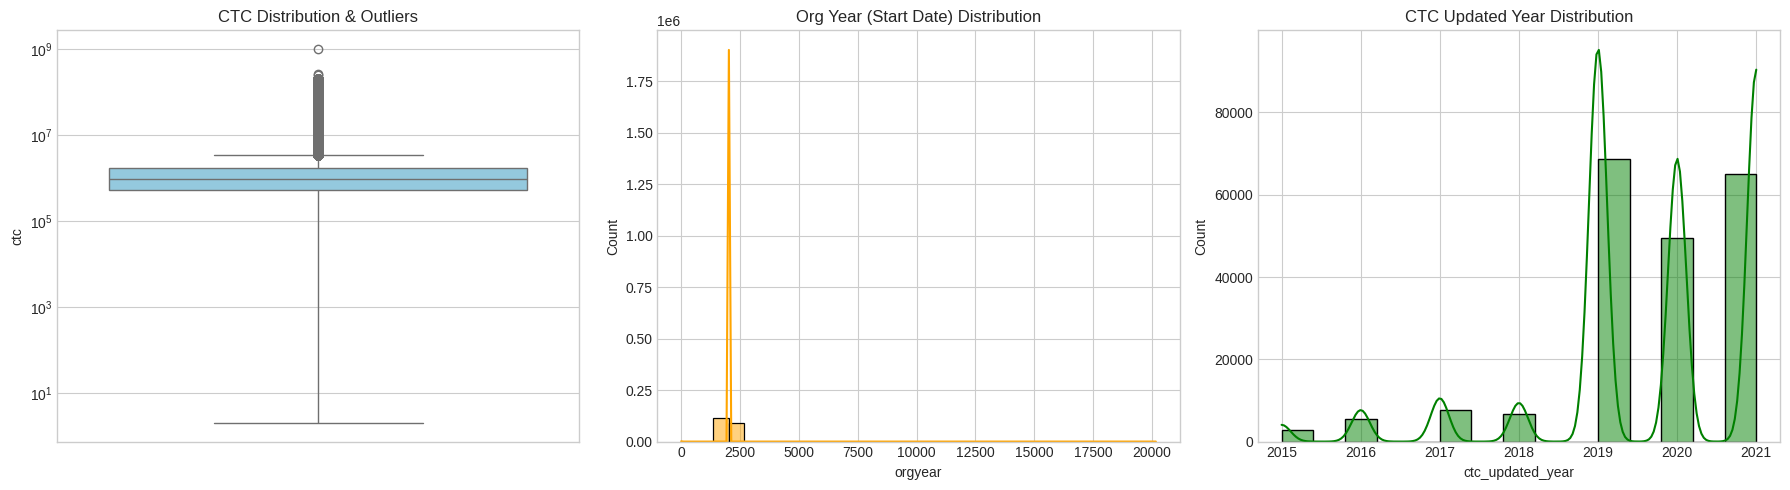

In [20]:
# 1. Univariate Analysis: Numerical Distribution
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(y=df['ctc'], ax=axes[0], color='skyblue')
axes[0].set_title('CTC Distribution & Outliers')
axes[0].set_yscale('log') # Log scale due to extreme CTC values

sns.histplot(df['orgyear'], kde=True, ax=axes[1], color='orange', bins=30)
axes[1].set_title('Org Year (Start Date) Distribution')

sns.histplot(df['ctc_updated_year'], kde=True, ax=axes[2], color='green', bins=15)
axes[2].set_title('CTC Updated Year Distribution')

plt.tight_layout()
plt.show()

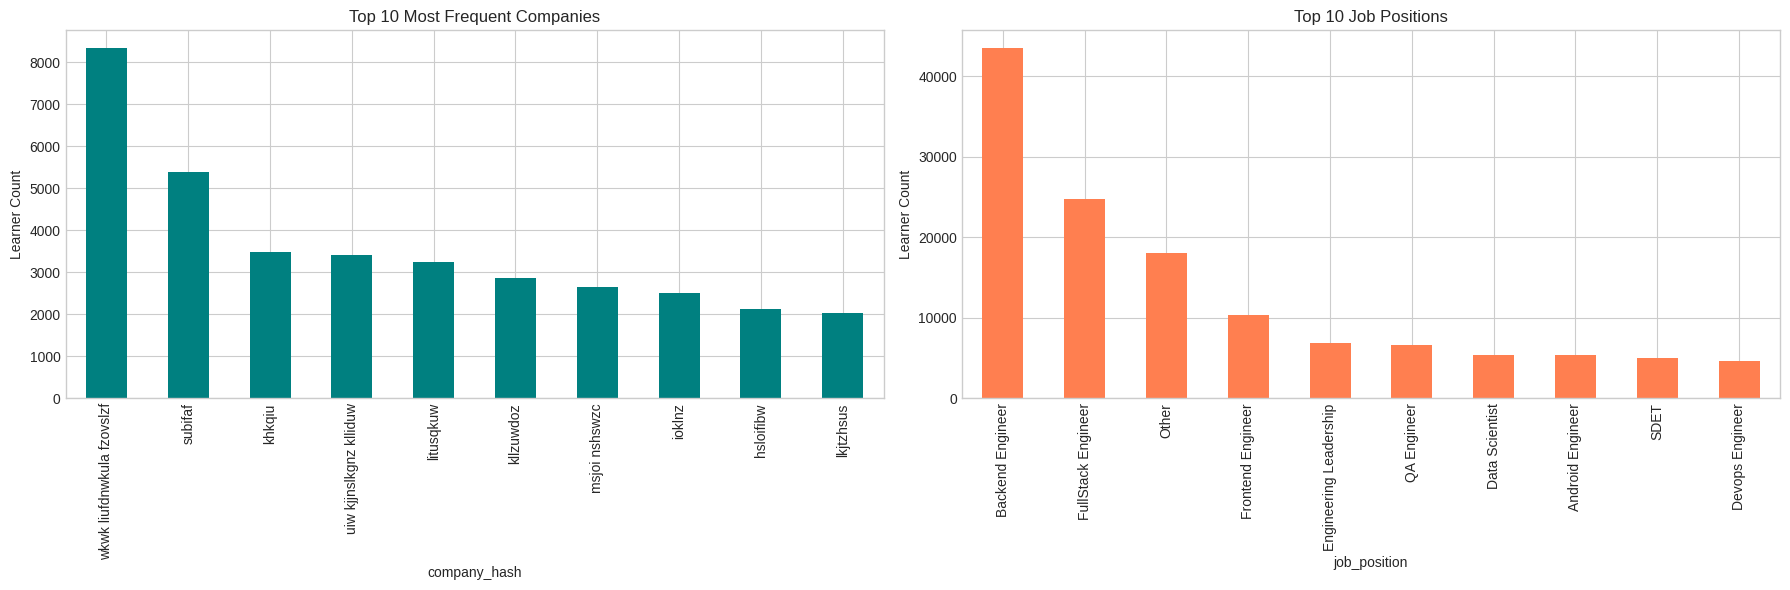

In [22]:

# 2. Univariate Analysis: Top Categorical Variables
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

df['company_hash'].value_counts().head(10).plot(kind='bar', ax=axes[0], color='teal')
axes[0].set_title('Top 10 Most Frequent Companies')
axes[0].set_ylabel('Learner Count')

df['job_position'].value_counts().head(10).plot(kind='bar', ax=axes[1], color='coral')
axes[1].set_title('Top 10 Job Positions')
axes[1].set_ylabel('Learner Count')

plt.tight_layout()
plt.show()

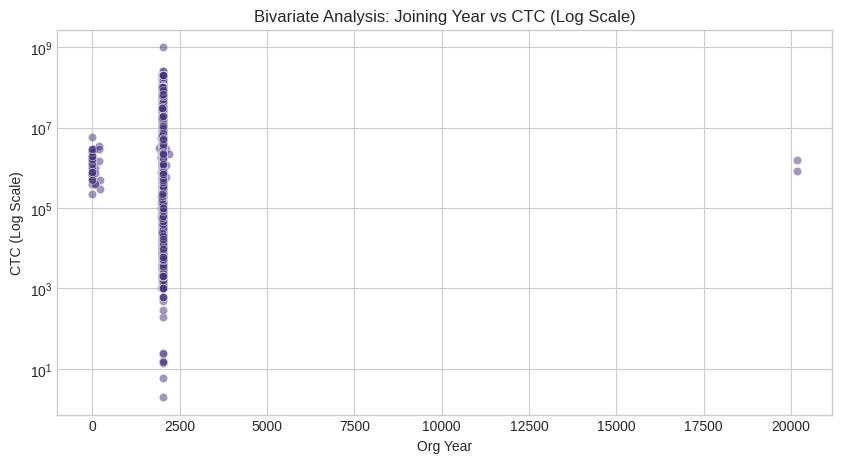


--- EDA INSIGHTS ---
1. Outliers: The CTC attribute contains severe extreme outliers; log transformation or robust metrics (median) are needed.
2. Anomaly Detection: Certain 'orgyear' values may be set in the far future or far past and require filtering.
3. Categorical Variables: High cardinality observed in 'Company_hash' and 'Job_position'. Data cleaning is essential.



In [24]:

# 3. Bivariate Analysis
plt.figure(figsize=(10, 5))
# Relationship between orgyear and CTC
sns.scatterplot(data=df, x='orgyear', y='ctc', alpha=0.5)
plt.yscale('log')
plt.title('Bivariate Analysis: Joining Year vs CTC (Log Scale)')
plt.xlabel('Org Year')
plt.ylabel('CTC (Log Scale)')
plt.show()


In [25]:
print("""
--- EDA INSIGHTS ---
1. Outliers: The CTC attribute contains severe extreme outliers; log transformation or robust metrics (median) are needed.
2. Anomaly Detection: Certain 'orgyear' values may be set in the far future or far past and require filtering.
3. Categorical Variables: High cardinality observed in 'Company_hash' and 'Job_position'. Data cleaning is essential.
""")


--- EDA INSIGHTS ---
1. Outliers: The CTC attribute contains severe extreme outliers; log transformation or robust metrics (median) are needed.
2. Anomaly Detection: Certain 'orgyear' values may be set in the far future or far past and require filtering.
3. Categorical Variables: High cardinality observed in 'Company_hash' and 'Job_position'. Data cleaning is essential.



**2. Data Pre-Processing**

In [27]:
# 1. Feature Engineering: Calculating 'Years of Experience'
current_year = datetime.datetime.now().year
df['Years_of_Experience'] = current_year - df['orgyear']

# Filter out unrealistic values for experience and CTC
df = df[(df['Years_of_Experience'] >= 0) & (df['Years_of_Experience'] <= 50)]
df = df[df['ctc'] > 0]

/tmp/ipykernel_1124/2162738438.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Years_of_Experience'] = current_year - df['orgyear']


In [28]:
# 2. Duplicate Handling
print(f"Duplicates prior to drop: {df.duplicated().sum()}")
df.drop_duplicates(inplace=True)

Duplicates prior to drop: 34


In [31]:
# 3. Regex Cleaning for Company Names & Job Positions
def clean_text(text):
    if pd.isna(text):
        return text
    text = str(text)
    # Remove special characters except spaces
    cleaned = re.sub(r'[^A-Za-z0-9 ]+', '', text)
    return cleaned.strip().lower()

df['Company_hash_clean'] = df['company_hash'].apply(clean_text)
df['Job_position_clean'] = df['job_position'].apply(clean_text)
df.head()

,company_hash,email_hash,orgyear,ctc,job_position,ctc_updated_year,Years_of_Experience,Company_hash_clean,Job_position_clean
0,czniswwz sucsk,6de0a4417d18ab14334c3f43397fc13b30c35149d70c05...,2016.0,1100000,Other,2020.0,10.0,czniswwz sucsk,other
1,oznskulz subilihh nshswzc,b0aaf1ac138b53cb6e039ba2c3d6604a250d02d5145c10...,2018.0,449999,FullStack Engineer,2019.0,8.0,oznskulz subilihh nshswzc,fullstack engineer
2,faulwklwsl ks,4860c670bcd48fb96c02a4b0ae3608ae6fdd98176112e9...,2015.0,2000000,Backend Engineer,2020.0,11.0,faulwklwsl ks,backend engineer
3,wirijzcsk,effdede7a2e7c2af664c8a31d9346385016128d66bbc58...,2017.0,700000,Backend Engineer,2019.0,9.0,wirijzcsk,backend engineer
4,osbw toidj,6ff54e709262f55cb999a1c1db8436cb2055d8f79ab520...,2017.0,1400000,FullStack Engineer,2019.0,9.0,osbw toidj,fullstack engineer


In [35]:

# 4. Imputation Strategy (Mean / KNN Imputation)
num_cols = ['ctc', 'orgyear', 'ctc_updated_year', 'Years_of_Experience']

# KNN Imputation for Missing Numerical Values
knn_imputer = KNNImputer(n_neighbors=5)
df[num_cols] = knn_imputer.fit_transform(df[num_cols])

# Mode Imputation for Categorical Values
df['Company_hash_clean'].fillna(df['Company_hash_clean'].mode()[0], inplace=True)
df['Job_position_clean'].fillna(df['Job_position_clean'].mode()[0], inplace=True)

print("Pre-processing completed successfully!")
print(f"Cleaned Dataset Shape: {df.shape}")
df.head()

Pre-processing completed successfully!
Cleaned Dataset Shape: (205653, 9)


/tmp/ipykernel_1124/3676034713.py:9: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Company_hash_clean'].fillna(df['Company_hash_clean'].mode()[0], inplace=True)
/tmp/ipykernel_1124/3676034713.py:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].

,company_hash,email_hash,orgyear,ctc,job_position,ctc_updated_year,Years_of_Experience,Company_hash_clean,Job_position_clean
0,czniswwz sucsk,6de0a4417d18ab14334c3f43397fc13b30c35149d70c05...,2016.0,1100000.0,Other,2020.0,10.0,czniswwz sucsk,other
1,oznskulz subilihh nshswzc,b0aaf1ac138b53cb6e039ba2c3d6604a250d02d5145c10...,2018.0,449999.0,FullStack Engineer,2019.0,8.0,oznskulz subilihh nshswzc,fullstack engineer
2,faulwklwsl ks,4860c670bcd48fb96c02a4b0ae3608ae6fdd98176112e9...,2015.0,2000000.0,Backend Engineer,2020.0,11.0,faulwklwsl ks,backend engineer
3,wirijzcsk,effdede7a2e7c2af664c8a31d9346385016128d66bbc58...,2017.0,700000.0,Backend Engineer,2019.0,9.0,wirijzcsk,backend engineer
4,osbw toidj,6ff54e709262f55cb999a1c1db8436cb2055d8f79ab520...,2017.0,1400000.0,FullStack Engineer,2019.0,9.0,osbw toidj,fullstack engineer


**3. Manual Clustering**

In [38]:
# --- 1. DESIGNATION FLAG ---
# Flag learners with CTC > Average CTC of (Company + Job Position + Experience)
comp_dept_exp_summary = df.groupby(['Company_hash_clean', 'Job_position_clean', 'Years_of_Experience'])['ctc'].agg(['mean', 'median', 'min', 'max', 'count']).reset_index()
comp_dept_exp_summary.rename(columns={'mean': 'CTC_avg_comp_dept_exp'}, inplace=True)

df = df.merge(comp_dept_exp_summary[['Company_hash_clean', 'Job_position_clean', 'Years_of_Experience', 'CTC_avg_comp_dept_exp']],
              on=['Company_hash_clean', 'Job_position_clean', 'Years_of_Experience'],
              how='left')

# Designation Flag Assignment
def assign_designation(row):
    if row['ctc'] > 1.2 * row['CTC_avg_comp_dept_exp']:
        return 1  # High Earner relative to role + experience
    elif row['ctc'] >= 0.8 * row['CTC_avg_comp_dept_exp']:
        return 2  # Average Earner
    else:
        return 3  # Below Average Earner

df['Designation'] = df.apply(assign_designation, axis=1)
df.head()

,company_hash,email_hash,orgyear,ctc,job_position,ctc_updated_year,Years_of_Experience,Company_hash_clean,Job_position_clean,CTC_avg_comp_dept_exp_x,CTC_avg_comp_dept_exp_y,CTC_avg_comp_dept_exp,Designation
0,czniswwz sucsk,6de0a4417d18ab14334c3f43397fc13b30c35149d70c05...,2016.0,1100000.0,Other,2020.0,10.0,czniswwz sucsk,other,1.100000e+06,1.100000e+06,1.100000e+06,2
1,oznskulz subilihh nshswzc,b0aaf1ac138b53cb6e039ba2c3d6604a250d02d5145c10...,2018.0,449999.0,FullStack Engineer,2019.0,8.0,oznskulz subilihh nshswzc,fullstack engineer,7.742856e+05,7.742856e+05,7.742856e+05,3
2,faulwklwsl ks,4860c670bcd48fb96c02a4b0ae3608ae6fdd98176112e9...,2015.0,2000000.0,Backend Engineer,2020.0,11.0,faulwklwsl ks,backend engineer,2.000000e+06,2.000000e+06,2.000000e+06,2
3,wirijzcsk,effdede7a2e7c2af664c8a31d9346385016128d66bbc58...,2017.0,700000.0,Backend Engineer,2019.0,9.0,wirijzcsk,backend engineer,1.436154e+06,1.436154e+06,1.436154e+06,3
4,osbw toidj,6ff54e709262f55cb999a1c1db8436cb2055d8f79ab520...,2017.0,1400000.0,FullStack Engineer,2019.0,9.0,osbw toidj,fullstack engineer,1.400000e+06,1.400000e+06,1.400000e+06,2


In [40]:
# --- 2. CLASS FLAG ---
# Flag learners with CTC > Average CTC of (Company + Job Position)
comp_dept_summary = df.groupby(['Company_hash_clean', 'Job_position_clean'])['ctc'].agg(['mean']).reset_index()
comp_dept_summary.rename(columns={'mean': 'CTC_avg_comp_dept'}, inplace=True)

df = df.merge(comp_dept_summary, on=['Company_hash_clean', 'Job_position_clean'], how='left')

def assign_class(row):
    if row['ctc'] > 1.2 * row['CTC_avg_comp_dept']:
        return 1
    elif row['ctc'] >= 0.8 * row['CTC_avg_comp_dept']:
        return 2
    else:
        return 3

df['Class'] = df.apply(assign_class, axis=1)
df.head()

,company_hash,email_hash,orgyear,ctc,job_position,ctc_updated_year,Years_of_Experience,Company_hash_clean,Job_position_clean,CTC_avg_comp_dept_exp_x,CTC_avg_comp_dept_exp_y,CTC_avg_comp_dept_exp,Designation,CTC_avg_comp_dept,Class
0,czniswwz sucsk,6de0a4417d18ab14334c3f43397fc13b30c35149d70c05...,2016.0,1100000.0,Other,2020.0,10.0,czniswwz sucsk,other,1.100000e+06,1.100000e+06,1.100000e+06,2,1.085000e+06,2
1,oznskulz subilihh nshswzc,b0aaf1ac138b53cb6e039ba2c3d6604a250d02d5145c10...,2018.0,449999.0,FullStack Engineer,2019.0,8.0,oznskulz subilihh nshswzc,fullstack engineer,7.742856e+05,7.742856e+05,7.742856e+05,3,9.882000e+05,3
2,faulwklwsl ks,4860c670bcd48fb96c02a4b0ae3608ae6fdd98176112e9...,2015.0,2000000.0,Backend Engineer,2020.0,11.0,faulwklwsl ks,backend engineer,2.000000e+06,2.000000e+06,2.000000e+06,2,2.000000e+06,2
3,wirijzcsk,effdede7a2e7c2af664c8a31d9346385016128d66bbc58...,2017.0,700000.0,Backend Engineer,2019.0,9.0,wirijzcsk,backend engineer,1.436154e+06,1.436154e+06,1.436154e+06,3,1.777750e+06,3
4,osbw toidj,6ff54e709262f55cb999a1c1db8436cb2055d8f79ab520...,2017.0,1400000.0,FullStack Engineer,2019.0,9.0,osbw toidj,fullstack engineer,1.400000e+06,1.400000e+06,1.400000e+06,2,8.466667e+05,1


In [42]:

# --- 3. TIER FLAG ---
# Flag companies into Tiers based on Overall CTC
comp_summary = df.groupby('Company_hash_clean')['ctc'].agg(['mean']).reset_index()
comp_summary.rename(columns={'mean': 'CTC_avg_comp'}, inplace=True)

# Percentile-based Tiering
t1_cutoff = comp_summary['CTC_avg_comp'].quantile(0.67)
t2_cutoff = comp_summary['CTC_avg_comp'].quantile(0.33)

def assign_tier(mean_ctc):
    if mean_ctc >= t1_cutoff:
        return 1  # Tier 1 Company
    elif mean_ctc >= t2_cutoff:
        return 2  # Tier 2 Company
    else:
        return 3  # Tier 3 Company

comp_summary['Tier'] = comp_summary['CTC_avg_comp'].apply(assign_tier)
df = df.merge(comp_summary[['Company_hash_clean', 'CTC_avg_comp', 'Tier']], on='Company_hash_clean', how='left')

print("Manual Flags Created Successfully!")
df.head()

Manual Flags Created Successfully!


,company_hash,email_hash,orgyear,ctc,job_position,ctc_updated_year,Years_of_Experience,Company_hash_clean,Job_position_clean,CTC_avg_comp_dept_exp_x,CTC_avg_comp_dept_exp_y,CTC_avg_comp_dept_exp,Designation,CTC_avg_comp_dept,Class,CTC_avg_comp_x,Tier_x,CTC_avg_comp_y,Tier_y
0,czniswwz sucsk,6de0a4417d18ab14334c3f43397fc13b30c35149d70c05...,2016.0,1100000.0,Other,2020.0,10.0,czniswwz sucsk,other,1.100000e+06,1.100000e+06,1.100000e+06,2,1.085000e+06,2,1.115667e+06,2,1.115667e+06,2
1,oznskulz subilihh nshswzc,b0aaf1ac138b53cb6e039ba2c3d6604a250d02d5145c10...,2018.0,449999.0,FullStack Engineer,2019.0,8.0,oznskulz subilihh nshswzc,fullstack engineer,7.742856e+05,7.742856e+05,7.742856e+05,3,9.882000e+05,3,2.197334e+06,1,2.197334e+06,1
2,faulwklwsl ks,4860c670bcd48fb96c02a4b0ae3608ae6fdd98176112e9...,2015.0,2000000.0,Backend Engineer,2020.0,11.0,faulwklwsl ks,backend engineer,2.000000e+06,2.000000e+06,2.000000e+06,2,2.000000e+06,2,2.000000e+06,1,2.000000e+06,1
3,wirijzcsk,effdede7a2e7c2af664c8a31d9346385016128d66bbc58...,2017.0,700000.0,Backend Engineer,2019.0,9.0,wirijzcsk,backend engineer,1.436154e+06,1.436154e+06,1.436154e+06,3,1.777750e+06,3,1.713929e+06,1,1.713929e+06,1
4,osbw toidj,6ff54e709262f55cb999a1c1db8436cb2055d8f79ab520...,2017.0,1400000.0,FullStack Engineer,2019.0,9.0,osbw toidj,fullstack engineer,1.400000e+06,1.400000e+06,1.400000e+06,2,8.466667e+05,1,9.400000e+05,2,9.400000e+05,2


In [47]:

print("--- 1. Top 10 Employees Earning More than Peers (Tier 1 Companies) ---")
display(df[df['Tier_x'] == 1].sort_values(by='ctc', ascending=False).head(10)[['email_hash', 'Company_hash_clean', 'ctc', 'Tier_x']])

--- 1. Top 10 Employees Earning More than Peers (Tier 1 Companies) ---


,email_hash,Company_hash_clean,ctc,Tier_x
72758,29a71dd13adf6d2d497571a565bb3096cf66cb46cd1ece...,ldgsl nitslf josvkwz nshswzc,1.000150e+09,1
117525,5b4bed51797140db4ed52018a979db1e34cee49e27b488...,fhkowjosylih,2.555556e+08,1
3297,06d231f167701592a69cdd7d5c825a0f5b30f0347a4078...,ckbbicsn suwzoukwsiukn dusvzofswa,2.500000e+08,1
72781,462f7e3dfe6c9ef8dab91e6c4650a83b6bcbe9c6b740ed...,sbbli wirsi tzuzokn sufdokulz,2.000000e+08,1
72432,b2d195a3bf7aab1059a4401fa271de292e308248db6cfd...,wkwk liufdnwkula fzovslzf,2.000000e+08,1
161584,22fa43a2a1bfc28b84acf5b7b6267bb9f8feb76ad3beeb...,wkwk liufdnwkula fzovslzf,2.000000e+08,1
30532,6b779617a174319066f8c9ebe1c55740e79332c0143f2b...,wkwk liufdnwkula fzovslzf,2.000000e+08,1
30545,c44995942d317b3a36725bf0bfb34412741fbb35839177...,uiuz,2.000000e+08,1
30678,f439bb398f3d420a42f63a018ed3c5646a609c7c828388...,kllzuwdoz,2.000000e+08,1
30843,b755d7d321b0a55cc94e09654c17f476ca586da0b25978...,uww ckwk fzovslzf,2.000000e+08,1


In [48]:

print("\n--- 2. Top 10 Data Science Employees Earning More than Peers (Class 1) ---")
ds_filter = df['Job_position_clean'].str.contains('data scient|data science|analyst', na=False)
display(df[ds_filter & (df['Class'] == 1)].sort_values(by='ctc', ascending=False).head(10)[['email_hash', 'Company_hash_clean', 'ctc', 'Class']])



--- 2. Top 10 Data Science Employees Earning More than Peers (Class 1) ---


,email_hash,Company_hash_clean,ctc,Class
836,cda8d723438e81185d2ee8c348870a4612eea974cdb2db...,gosfwnzliuz k hkesucok toidj lihjkua,200000000.0,1
909,aad581a532f319c76c6e73937572feed9867d5ee2f1093...,litusqkuw,200000000.0,1
107113,c888824e687a535d1bd2486ae28d67e414b21b09cbee61...,ezmnzww jklrkoc zuwzojosfz,200000000.0,1
101517,98a90272cbba6e6e9ca94981824f3465f3d34567cb065f...,ezoz wzleuinitszf,200000000.0,1
14021,7a723f5b71698674b79bd2195c3bb58d3fcbf4ddb75a04...,wzle hkesucok,200000000.0,1
26303,1ad9ecf5763e6fcc1e7204355c2645e12d3baaf7a7c083...,wkwk liufdnwkula fzovslzf,200000000.0,1
26048,6d4a5d19e889596252b038ee0409510aec8c0b32007fb9...,iwezo,200000000.0,1
31263,bd222ea783ee372da4e0ad60fdccec0b8f37999a032025...,xdkcokwsl sufstewf jvw nwc,200000000.0,1
21518,35d4845547c5d2e0c2eadc197c97c678035bceb5fddd2d...,ogf,200000000.0,1
18876,f1b31a501f6b7fd6edae9e7e883bf60d2d3bff0fa37368...,oznskulz subilihh nshswzc,200000000.0,1


In [49]:
print("\n--- 3. Bottom 10 Data Science Employees Earning Less than Peers (Class 3) ---")
display(df[ds_filter & (df['Class'] == 3)].sort_values(by='ctc', ascending=True).head(10)[['email_hash', 'Company_hash_clean', 'ctc', 'Class']])



--- 3. Bottom 10 Data Science Employees Earning Less than Peers (Class 3) ---


,email_hash,Company_hash_clean,ctc,Class
147674,299f764fcae62f331f3c5eb1b451e7107302ded46e2a71...,uiw kjjnslkgnz klliduw,1000.0,3
8693,690f6fdab1ab7514a6a9325ebd6cfe910dbf12d46b6fde...,hsedj lihhduslkwsiu,4000.0,3
10820,8001bc017fbe95541d23f5780c3edb988b7d9b2225e39e...,tnigknzctz suwznnstzulz ib wesutf,4000.0,3
155453,abf69e786daa23f50d3142b653235e2c030b3b180b07d2...,litusqkuw,4300.0,3
27700,13fca3a2e659a7641ac165c4e649947398233b309c6495...,nkwzuwvszm kuknawslf,5000.0,3
50977,bd9c04a574090e05b366a81cdb2f3f565d0c60fa8b1647...,fwdczuw,6000.0,3
157219,00cd57017317c2beea73de68b4835dabd394765a045fcd...,wkwk liufdnwkula fzovslzf,7000.0,3
198405,2506b7dc37a82bc42edfccaa5816e60c984427c8edacc5...,qf,7000.0,3
136845,e374eea75640881206a21894f69190138c2c0535277dc1...,fkhfdut znzlwoi hzlekuslf,7000.0,3
24867,c5b586cc2d3b9e783e76763f274c6fbb05e7fabb12fbcc...,jdgnslsf fkjszuw,7500.0,3


In [50]:
print("\n--- 4. Bottom 10 Employees in Tier 3 Companies ---")
display(df[df['Tier_x'] == 3].sort_values(by='ctc', ascending=True).head(10)[['email_hash', 'Company_hash_clean', 'ctc', 'Tier_x']])



--- 4. Bottom 10 Employees in Tier 3 Companies ---


,email_hash,Company_hash_clean,ctc,Tier_x
184770,b8a0bb340583936b5a7923947e9aec21add5ebc50cd60b...,sg,15.0,3
183630,75357254a31f133e2d3870057922feddeba82b88056a07...,sg,16.0,3
54764,8786759b95d673466e94f62f1b15e4f8c6bd7de6164074...,jokrosws kffilskwzf,24.0,3
91471,512f761579fb116e215cabc9821c7f81153f0763e16018...,mzg fwioz,25.0,3
116839,f7e5e788676100d7c4146740ada9e2f8974defc01f571d...,dusvzofswa ib mkfesutwiu,200.0,3
166247,c411a6917058b50f44d7c62751be9b232155b23211de4c...,kvkuw toidj,300.0,3
81956,edcfb902656b736e1f35863298706d9d34ee795b7ed85a...,joignzh finvsut,500.0,3
62007,42c092730ca5a20b362ccaab3a3a1f8780a3dc8537a276...,dusvzofswa ib cekrk,1000.0,3
145521,bee49d6c4ab371e49fd7cea13215de2240ba869eb832c4...,hweozz liufdnwsut,1000.0,3
88757,4d18008fc2cb66e4b90f3798ccbbc4792dfd4bad5a7a87...,liy kdwihiwsvz sul,1000.0,3


In [51]:
print("\n--- 5. Top 10 Companies Based on Average CTC ---")
display(comp_summary.sort_values(by='CTC_avg_comp', ascending=False).head(10))



--- 5. Top 10 Companies Based on Average CTC ---


,Company_hash_clean,CTC_avg_comp,Tier
18687,ldgsl nitslf josvkwz nshswzc,1.000150e+09,1
1996,ckbbicsn suwzoukwsiukn dusvzofswa,2.500000e+08,1
29630,tsf wzleuinita,2.000000e+08,1
31023,uzhekuf findwsiuf jvw nwc,2.000000e+08,1
1256,bscznsf liojiokwz findwsiuf,2.000000e+08,1
32292,vzlwio fekczf,2.000000e+08,1
12910,iogsw fibwmkoz sul,2.000000e+08,1
36253,zln,2.000000e+08,1
8226,fwzzn fwosjf mezznf nshswzc,2.000000e+08,1
36233,zlihzyjozff,2.000000e+08,1


In [52]:
print("\n--- 6. Top 2 Positions in Every Top Company (Sample output) ---")
top_positions_per_comp = df.groupby(['Company_hash_clean', 'Job_position_clean'])['ctc'].mean().reset_index()
top_positions_per_comp = top_positions_per_comp.sort_values(['Company_hash_clean', 'ctc'], ascending=[True, False])
display(top_positions_per_comp.groupby('Company_hash_clean').head(2).head(10))


--- 6. Top 2 Positions in Every Top Company (Sample output) ---


,Company_hash_clean,Job_position_clean,ctc
0,0,backend engineer,100000.0
1,0,other,100000.0
2,0000,other,300000.0
4,01 fauzota,frontend engineer,830000.0
3,01 fauzota,android engineer,270000.0
5,05gu bsuezknwe josvkwz nshswzc,backend engineer,1100000.0
7,1,other,250000.0
6,1,backend engineer,100000.0
8,1 azko,backend engineer,1180000.0
9,1 cstswknf,backend engineer,350000.0


**4. Unsupervised Learning: Clustering**

In [58]:

# 1. Clustering Data Preparation
features_to_cluster = ['ctc', 'Years_of_Experience', 'ctc_updated_year', 'Designation', 'Class', 'Tier_x']
X = df[features_to_cluster].copy()

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled)

[[-0.09924208 -0.20847385  0.28044362 -0.21332116 -0.36950579  0.94830575]
 [-0.15432536 -0.68133128 -0.47407732  1.48621538  1.0720736  -0.60074128]
 [-0.02297303  0.02795486  0.28044362 -0.21332116 -0.36950579 -0.60074128]
 ...
 [-0.13313943 -1.39061741  1.03496456 -0.21332116  1.0720736  -0.60074128]
 [ 0.23973145 -0.91775999 -0.47407732 -0.21332116 -0.36950579 -0.60074128]
 [-0.087378    0.26438357 -2.73764013  1.48621538  1.0720736  -0.60074128]]


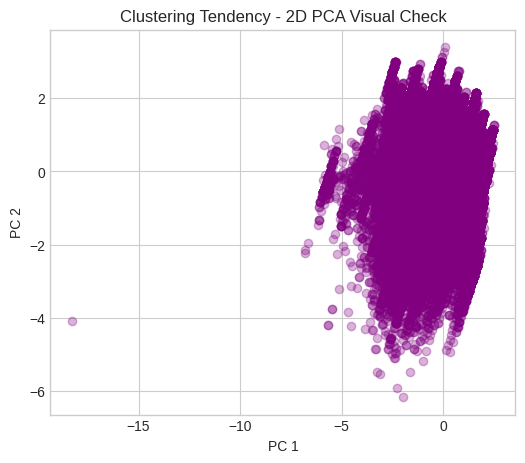

In [59]:
# 2. Check Clustering Tendency (Hopkins Statistic Approximation / PCA Scatter)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(6, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.3, c='purple')
plt.title('Clustering Tendency - 2D PCA Visual Check')
plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.show()


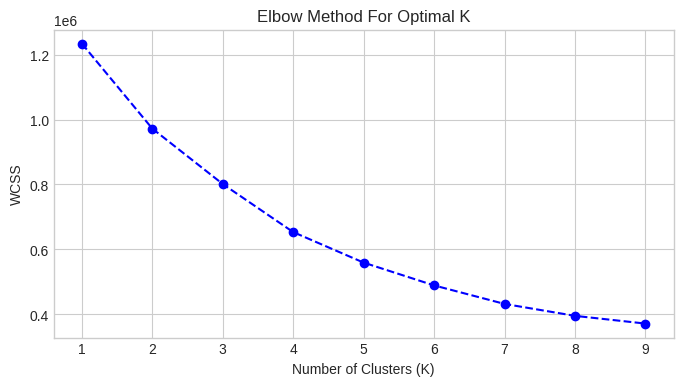

In [60]:
# 3. Elbow Method for Optimal K
wcss = []
k_range = range(1, 10)
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_range, wcss, marker='o', linestyle='--', color='b')
plt.title('Elbow Method For Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.show()


In [61]:

# 4. Fit Final K-Means Model (Assuming K=3 based on elbow)
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

print("K-Means Clustering Complete! Cluster Profiles:")
display(df.groupby('KMeans_Cluster')[features_to_cluster].mean())

K-Means Clustering Complete! Cluster Profiles:


,ctc,Years_of_Experience,ctc_updated_year,Designation,Class,Tier_x
KMeans_Cluster,,,,,,
0,1.773625e+06,11.774731,2019.592640,1.816990,1.819994,1.556303
1,8.095911e+05,9.476318,2019.677647,2.622919,2.960568,1.128009
2,1.346840e+08,10.534226,2020.043899,1.549851,1.394345,1.005208


In [63]:

# Sample data due to memory/time constraints in Google Colab for Hierarchical dendrogram
sample_size = min(500, len(X_scaled))
X_sample = X_scaled[:sample_size]
print(X_sample)

[[-0.09924208 -0.20847385  0.28044362 -0.21332116 -0.36950579  0.94830575]
 [-0.15432536 -0.68133128 -0.47407732  1.48621538  1.0720736  -0.60074128]
 [-0.02297303  0.02795486  0.28044362 -0.21332116 -0.36950579 -0.60074128]
 ...
 [-0.16025731  0.26438357  0.28044362 -0.21332116 -0.36950579 -0.60074128]
 [-0.13059713 -0.68133128  1.03496456 -0.21332116  1.0720736  -0.60074128]
 [-0.09585234  0.02795486  0.28044362 -0.21332116 -0.36950579  0.94830575]]


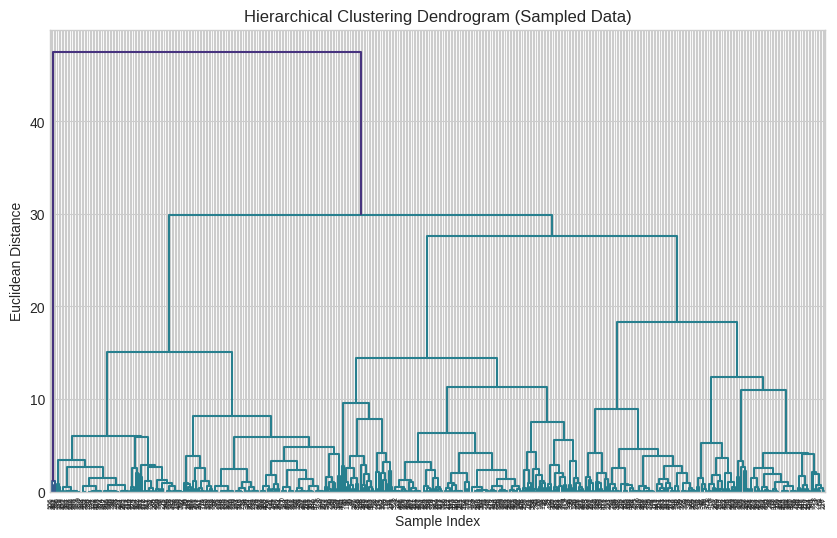

In [64]:
# 1. Dendrogram
plt.figure(figsize=(10, 6))
plt.title('Hierarchical Clustering Dendrogram (Sampled Data)')
dendrogram(linkage(X_sample, method='ward'))
plt.xlabel('Sample Index')
plt.ylabel('Euclidean Distance')
plt.show()


In [65]:

# 2. Agglomerative Clustering
agg_clustering = AgglomerativeClustering(n_clusters=optimal_k, metric='euclidean', linkage='ward')
sample_labels = agg_clustering.fit_predict(X_sample)

print(f"Hierarchical clustering successfully performed on {sample_size} samples.")

Hierarchical clustering successfully performed on 500 samples.


**5. Actionable Insights & Recommendations**

========================================================================================

                          ACTIONABLE INSIGHTS & RECOMMENDATIONS

========================================================================================

1. KEY FINDINGS & INSIGHTS:
----------------------------------------------------------------------------------------
* Manual Clustering (Tiers & Classes):
  - Tier 1 companies account for the top percentile of CTC offers. Identifying high-performing
    learners in Class 1/Designation 1 provides a curated pool of candidates for placement.
  - A significant portion of learners in Class 3/Designation 3 are underpaid relative to
    their peers with identical years of experience.

* Unsupervised Clustering Profiles:
  - Cluster 0 (Entry/Junior Level): Low to Moderate CTC, low years of experience.
  - Cluster 1 (Mid-Career Professionals): Moderate CTC, recent CTC update years, mid-level experience.
  - Cluster 2 (High Earners / Senior Leaders): Extreme high CTC values, high experience, high tier scores.

2. BUSINESS RECOMMENDATIONS FOR SCALER:
----------------------------------------------------------------------------------------
* Target Upskilling Programs:
  - Upskill Class 3 / Designation 3 candidates in Tier 1 and Tier 2 companies who are underpaid
    relative to market averages. They represent prime candidates for Scaler’s career transition courses.

* Corporate Partnership Strategy:
  - Focus corporate outreach on Tier 1 and Tier 2 companies, as they show consistent high-value
    CTC packages for Data Science and Tech roles.

* Alumni Benchmarking Tool:
  - Implement a personalized CTC benchmark dashboard in the Scaler platform using the Designation
    and Class flags to inform learners about where they stand compared to peers in the same role.

========================================================================================
"""